

# Homework 8 · Problem 3: Generating Random Samples from a CDF

Complete the Markdown and code cells marked **YOUR ANSWER** or
**YOUR CODE**.

The setup code and the numerical CDF function are provided.
Do not modify the instructor-provided cells.

Include your algorithm descriptions, implementation, figures,
and numerical comparisons in your completed notebook.

Run all cells in order before submission.

| Part | Provided by the instructor | Completed by students  |
|---|---|---|
| (a) Explicit CDF | The CDF formula | Derive the transformation, describe the algorithm, find the PDF |
| (b) Numerical CDF | The complete code cell labeled “Instructor-provided”; interval, tolerance, and search hint | Describe and implement the inverse search |
| (c) Simulation | Sample size, binning requirements, numerical differentiation formula | Generate samples, plot results, estimate probabilities, explain findings |

**How to run:** NumPy and Matplotlib are required.
Figures appear directly in the notebook.


## Problem Statement (15 points; three parts)

**(a) (4 points)** The first distribution has CDF

$$
F_1(x)=
\begin{cases}
0, & x\le 0,\\
x^2, & 0<x<1,\\
1, & x\ge 1.
\end{cases}
$$

Describe an algorithm that transforms $U\sim\operatorname{Unif}(0,1)$
into a sample from this distribution, and find its PDF.

**(b) (6 points)** The second distribution takes values in $[0,2]$.
Its CDF can be evaluated using the instructor-provided function $$F_2(x)$$.

Given $u\in(0,1)$, implement an interval search to find an $x$ satisfying

$$
|F_2(x)-u|\le 10^{-6}.
$$

State the initialization, interval update rule, and stopping criterion.
Do not call a built-in root-finding or inverse-function solver.
Use `F2(x)` to evaluate the CDF. Do not access the internal
CDF table or its auxiliary arrays to implement your inverse search.

**Hint:** Compare the CDF at the midpoint of the current interval with $u$.

Treat the supplied numerical CDF as the target CDF for this experiment.
Numerical integration error analysis is not required.

**(c) (5 points)** Generate $N=10000$ independent samples from each
distribution using your sampling algorithms. Use 40 equal-width bins
on $[0,1]$ and $[0,2]$, respectively.

For each distribution, plot a histogram normalized to have total area
one and overlay its PDF curve.

Use the PDF from part (a) for the first distribution.
For the second distribution, approximate the PDF using

$$
f_2(x)\approx
\frac{F_2(x+\delta)-F_2(x-\delta)}{2\delta},
\qquad \delta=10^{-3}.
$$

Plot this approximation only for

$$
\delta\le x\le 2-\delta.
$$

Report the proportion of samples satisfying $X\le 1/2$ for each
distribution, and compare it with the corresponding CDF at $1/2$.
Briefly interpret your results. Explain whether the inverse-search
tolerance of 1e-6 also requires the estimated probabilities to be
within 1e-6 of their target values.
Use random seed 140.


## 0. Setup

Run the following cell before starting the assignment.

It imports the required libraries, sets the sample size,
and initializes a random-number generator with seed 140.

Use this generator throughout the notebook. Do not reset its seed
before generating each sample.


In [1]:
# INSTRUCTOR-PROVIDED SETUP — DO NOT MODIFY.
# Run this setup cell at the beginning of each full notebook run.
# Do not reset or recreate rng in subsequent cells.
# Use the existing generator rng and sample size N throughout the notebook.
# Do not reset the seed in later cells.

import math
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(140)
N = 10000
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
print(f'Seed = 140; samples per distribution = {N}')


Seed = 140; samples per distribution = 10000


## 1. Part (a): The Explicit CDF


Derive a transformation that converts a uniform random number
into a sample from the first distribution provided in (a).

Describe the sampling algorithm step by step, and give the
piecewise expression for its PDF.

### **Answer (a)**

**Derivation (inverse transform / universality of the uniform).**
On $(0,1)$, $F_1(x)=x^2$ is continuous and strictly increasing, mapping $(0,1)$
onto $(0,1)$. For $u\in(0,1)$, solving $u=x^2$ with $x\in(0,1)$ gives
$$
F_1^{-1}(u)=\sqrt{u}.
$$
Let $U\sim\operatorname{Unif}(0,1)$ and $X=\sqrt U$. For $0<x<1$,
$$
\Pr(X\le x)=\Pr(\sqrt U\le x)=\Pr(U\le x^2)=x^2=F_1(x),
$$
and $\Pr(X\le x)=0$ for $x\le0$, $\Pr(X\le x)=1$ for $x\ge1$ since $X\in(0,1)$.
Hence $X=\sqrt U$ has CDF $F_1$.

**Algorithm.**
1. Generate $U\sim\operatorname{Unif}(0,1)$.
2. Return $X=\sqrt{U}$.

(For $N$ samples, apply this to $N$ independent uniforms $U_1,\dots,U_N$.)

**PDF.** Differentiating $F_1$,
$$
f_1(x)=F_1'(x)=
\begin{cases}
2x, & 0<x<1,\\
0, & \text{otherwise}.
\end{cases}
$$
(Check: $\int_0^1 2x\,dx=1$.)

In [2]:
# YOUR CODE — Generate samples from the first distribution.
# Inverse transform: F1^{-1}(u) = sqrt(u) for u in (0, 1).

u1 = rng.uniform(0.0, 1.0, size=N)
x1 = np.sqrt(u1)

print("u1 shape:", u1.shape, " x1 shape:", x1.shape)
print(f"x1 range: [{x1.min():.6f}, {x1.max():.6f}]")
print(f"Sample mean of x1 = {x1.mean():.4f}  (theoretical E[X] = 2/3 = {2/3:.4f})")

u1 shape: (10000,)  x1 shape: (10000,)
x1 range: [0.011698, 0.999965]
Sample mean of x1 = 0.6678  (theoretical E[X] = 2/3 = 0.6667)


## 2. Part (b): The Numerical CDF

Run the following code cell without modifying it.

The function $F_2(x)$ evaluates the target CDF at x.
The CDF is continuous and strictly increasing on [0, 2],
with $F_2(0)$ = 0 and $F_2(2)$ = 1.

You do not need to explain its internal implementation.
Use $F_2(x)$ as an interface; do not access its internal tables
or auxiliary arrays in your sampling algorithm.

In [3]:
# INSTRUCTOR-PROVIDED CDF — DO NOT MODIFY.
# Run this cell to define F2(x).
# F2 accepts one scalar x and returns its cumulative probability.
# In your sampling code, call F2(x) rather than accessing the
# internal arrays or auxiliary variables defined in this cell.

import math

_M = 20000
_dx = 2.0 / _M
_grid = [j * _dx for j in range(_M + 1)]
_weight = [math.exp(-(x ** 4)) for x in _grid]

_cdf = [0.0]
for j in range(_M):
    area = 0.5 * (_weight[j] + _weight[j + 1]) * _dx
    _cdf.append(_cdf[-1] + area)

_total = _cdf[-1]
_cdf = [value / _total for value in _cdf]


def F2(x):
    if x <= 0.0:
        return 0.0
    if x >= 2.0:
        return 1.0
    j = min(int(x / _dx), _M - 1)
    fraction = (x - _grid[j]) / _dx
    return (1.0 - fraction) * _cdf[j] + fraction * _cdf[j + 1]



### Example: Evaluating the CDF

The input to `F2` is a position, and its output is a cumulative
probability.

For example, `F2(0.5)` gives the probability that a random variable
from the second distribution is at most 0.5.

Run the following example to check that the supplied function
is available.


In [4]:
# Instructor-provided example.
print("F2(0.5) =", F2(0.5))

F2(0.5) = 0.5448539411542649


## 3. Part (b): Implement the Inverse Search


Describe your algorithm for finding x such that

$$
|F_2(x)-u|\le 10^{-6}.
$$

State the initial search interval, explain how the interval is
updated after each CDF evaluation, and specify the stopping criterion.

### **Answer (b): Bisection (interval-halving) search**

Because $F_2$ is continuous and strictly increasing on $[0,2]$ with
$F_2(0)=0$ and $F_2(2)=1$, for any $u\in(0,1)$ there is a unique
$x^*\in(0,2)$ with $F_2(x^*)=u$ (intermediate value theorem), and
$F_2(x)<u \iff x<x^*$. This monotonicity lets us halve the interval
that contains $x^*$ at each step.

**Initialization.** $L=0$, $R=2$. Then $F_2(L)=0<u<1=F_2(R)$, so $x^*\in(L,R)$.

**Each iteration.**
1. Compute the midpoint $m=(L+R)/2$ and evaluate $F_2(m)$.
2. **Stopping criterion:** if $|F_2(m)-u|\le 10^{-6}$, stop and return $x=m$.
3. **Interval update:**
   - if $F_2(m)<u$, then $x^*>m$, so set $L\leftarrow m$;
   - otherwise ($F_2(m)>u$), $x^*<m$, so set $R\leftarrow m$.

The invariant $F_2(L)<u<F_2(R)$ (i.e. $x^*\in(L,R)$) is kept, and the interval
length after $k$ steps is $2\cdot2^{-k}$. Since $F_2$ is piecewise linear with
slope at most $\max f_2=1/\int_0^2e^{-t^4}dt\approx1.10$, we have
$|F_2(m)-u|\le 1.11\,|m-x^*|\le 1.11\cdot 2^{1-k}$, so the stopping criterion
is met once $1.11\cdot2^{1-k}\le10^{-6}$, i.e. after at most $22$ iterations (empirically 22 at most, about 19 on average). As a safeguard, the loop is also capped
at 200 iterations (never reached in practice). Only `F2(x)` is called; no internal
tables or built-in root finders are used.

**Remark.** The stopping criterion is on the CDF value, not on $x$. Where $f_2$ is very small (the far right tail, $x\gtrsim1.5$), a CDF error of $10^{-6}$ can correspond to a larger error in $x$. This is harmless: only the CDF-scale error affects the distribution of the samples.

In [5]:
def inverse_F2(u, tol=1e-6):
    """Return x in [0, 2] with |F2(x) - u| <= tol, found by bisection."""
    if not (0.0 < u < 1.0):
        raise ValueError("u must satisfy 0 < u < 1")

    lo, hi = 0.0, 2.0              # F2(lo) = 0 < u < 1 = F2(hi)
    for _ in range(200):           # safeguard; ~21 iterations suffice
        mid = 0.5 * (lo + hi)
        F_mid = F2(mid)
        if abs(F_mid - u) <= tol:  # stopping criterion on the CDF value
            return mid
        if F_mid < u:              # root lies to the right of mid
            lo = mid
        else:                      # root lies to the left of mid
            hi = mid
    raise RuntimeError("Bisection did not reach the required tolerance")

### Check Your Implementation [Instructor-provided]

After completing `inverse_F2`, run the following check.

Passing this check verifies the required accuracy for one input.
It does not guarantee that the implementation is correct for
all inputs.


In [6]:
# Instructor-provided check.
# Run this check only after completing inverse_F2.
# A failure before completing the function is expected.
# Do not modify the check to make an incorrect implementation pass.
u_test = 0.7
x_test = inverse_F2(u_test)
try:
  assert 0.0 <= x_test <= 2.0
  assert abs(F2(x_test) - u_test) <= 1e-6
  print("The check passed for u = 0.7.")
except:
# An error might be raised if coding part above hasn't be completed
  print("The check failed for u = 0.7.")


The check passed for u = 0.7.


## 4. Part (c): Generate Samples from the Numerical CDF

Generate N independent uniform random numbers and apply your
`inverse_F2` function to obtain N samples from the second distribution.

Store the uniform random numbers in `u2` and the generated samples
in `x2`.

Check that every generated sample satisfies the required CDF
tolerance relative to its corresponding uniform input.


In [7]:
# YOUR CODE — Generate samples from the second distribution.

u2 = rng.uniform(0.0, 1.0, size=N)
x2 = np.array([inverse_F2(u) for u in u2])

print("u2 shape:", u2.shape, " x2 shape:", x2.shape)

# YOUR CODE — Check the numerical search accuracy.
errors = np.array([abs(F2(x) - u) for x, u in zip(x2, u2)])
print(f"Largest |F2(x2[i]) - u2[i]| over all {N} pairs = {errors.max():.3e}")
print("All errors <= 1e-6:", bool(np.all(errors <= 1e-6)))
print("All samples in [0, 2]:", bool(np.all((x2 >= 0.0) & (x2 <= 2.0))))
assert np.all(errors <= 1e-6)

u2 shape: (10000,)  x2 shape: (10000,)
Largest |F2(x2[i]) - u2[i]| over all 10000 pairs = 9.999e-07
All errors <= 1e-6: True
All samples in [0, 2]: True


## 5. Part (c): Plot the First Distribution

Plot a normalized histogram of `x1` using 40 equal-width bins
on [0, 1]. Overlay the PDF derived in part (a).

Include axis labels and a legend.

Plotting hint: `density=True` in Matplotlib's histogram function
normalizes the total area of the bars to one.


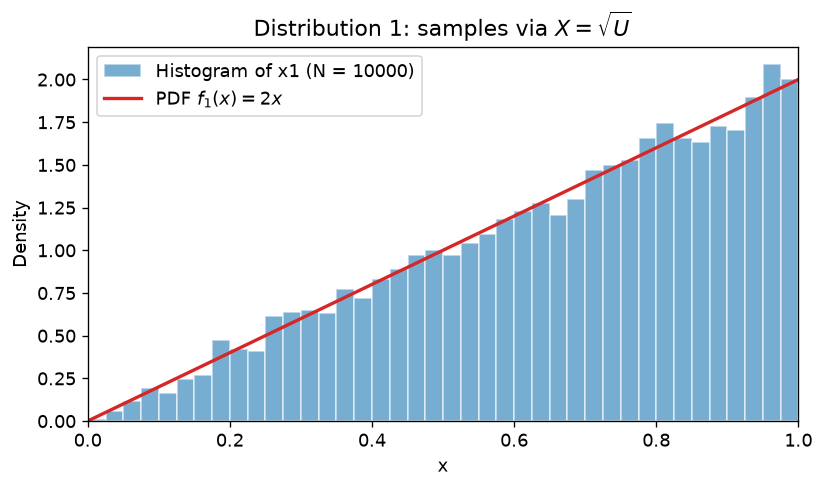

In [8]:
# YOUR CODE — Plot the first distribution.

bins1 = np.linspace(0.0, 1.0, 41)          # 40 equal-width bins on [0, 1]
grid1 = np.linspace(0.0, 1.0, 500)
pdf1 = 2.0 * grid1                         # f1(x) = 2x on (0, 1)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(x1, bins=bins1, density=True, alpha=0.6, color="tab:blue",
        edgecolor="white", label=f"Histogram of x1 (N = {N})")
ax.plot(grid1, pdf1, color="tab:red", lw=2, label=r"PDF $f_1(x)=2x$")
ax.set_xlabel("x")
ax.set_ylabel("Density")
ax.set_title("Distribution 1: samples via $X=\\sqrt{U}$")
ax.set_xlim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Part (c): Plot the Second Distribution

Approximate the PDF using

$$
f_2(x)\approx
\frac{F_2(x+\delta)-F_2(x-\delta)}{2\delta},
\qquad \delta=10^{-3}.
$$

Evaluate this approximation only for

$$
\delta\le x\le 2-\delta.
$$

Plot a normalized histogram of `x2` using 40 equal-width bins
on [0, 2], and overlay the approximate PDF curve.

Include axis labels and a legend.


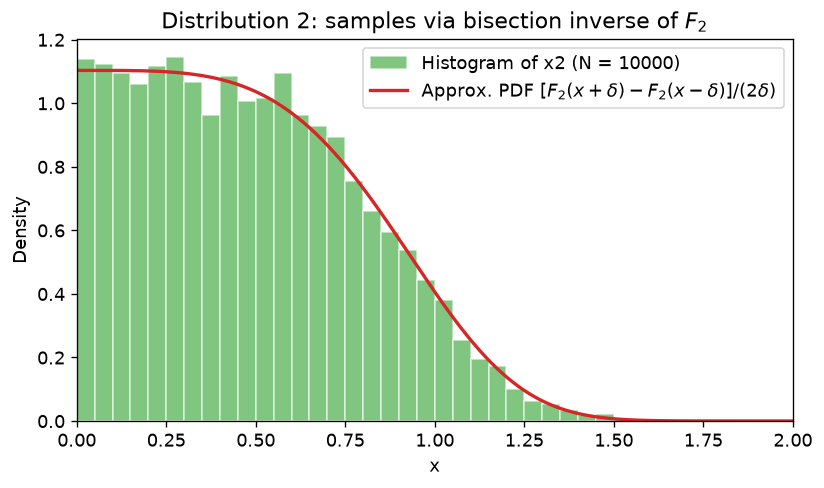

In [9]:
delta = 1e-3

# YOUR CODE — Approximate the second PDF and plot the results.

grid2 = np.linspace(delta, 2.0 - delta, 800)
pdf2 = np.array([(F2(x + delta) - F2(x - delta)) / (2.0 * delta) for x in grid2])

bins2 = np.linspace(0.0, 2.0, 41)          # 40 equal-width bins on [0, 2]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(x2, bins=bins2, density=True, alpha=0.6, color="tab:green",
        edgecolor="white", label=f"Histogram of x2 (N = {N})")
ax.plot(grid2, pdf2, color="tab:red", lw=2,
        label=r"Approx. PDF $[F_2(x+\delta)-F_2(x-\delta)]/(2\delta)$")
ax.set_xlabel("x")
ax.set_ylabel("Density")
ax.set_title("Distribution 2: samples via bisection inverse of $F_2$")
ax.set_xlim(0, 2)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Part (c): Compare Estimated and Target Probabilities

For each distribution, estimate the probability of X <= 0.5
using your generated samples.

Report the following in a clearly labeled table:

- The sample proportion.
- The target CDF value at 0.5.
- The absolute difference between these two values.


In [10]:
# YOUR CODE — Compare simulated and target probabilities.

def F1(x):
    if x <= 0.0:
        return 0.0
    if x >= 1.0:
        return 1.0
    return x ** 2

rows = []
for name, samples, F in [("Distribution 1 (F1)", x1, F1),
                         ("Distribution 2 (F2)", x2, F2)]:
    p_hat = np.count_nonzero(samples <= 0.5) / N
    target = F(0.5)
    se = math.sqrt(target * (1 - target) / N)   # Monte Carlo standard error
    rows.append((name, p_hat, target, abs(p_hat - target), se))

header = f"{'Distribution':<22}| {'Sample proportion':>17} | {'Target CDF':>10} | {'Absolute difference':>19} | {'MC std. error':>13}"
print(header)
print("-" * len(header))
for name, p_hat, target, diff, se in rows:
    print(f"{name:<22}| {p_hat:>17.4f} | {target:>10.6f} | {diff:>19.6f} | {se:>13.6f}")

Distribution          | Sample proportion | Target CDF | Absolute difference | MC std. error
--------------------------------------------------------------------------------------------
Distribution 1 (F1)   |            0.2523 |   0.250000 |            0.002300 |      0.004330
Distribution 2 (F2)   |            0.5401 |   0.544854 |            0.004754 |      0.004980


## 8. Part (c): Interpret Your Results


Briefly discuss whether the sample histograms agree with the
PDF curves and whether the estimated probabilities agree with
the target CDF values.

Does the inverse-search tolerance of 1e-6 imply that the estimated
probabilities must also be within 1e-6 of their target values?
Explain briefly.

### **Answer: interpretation**

**Histograms vs. PDFs.** In both figures the normalized histograms follow the
overlaid curves closely: the first histogram rises linearly like $f_1(x)=2x$,
and the second has the flat-then-rapidly-decaying shape of the density
proportional to $e^{-x^4}$ (almost no mass beyond $x\approx1.5$). The bar-to-bar
fluctuations around the curves have the size expected from random sampling
with $N=10000$ and 40 bins, so there is no visible systematic deviation. This
confirms that both the explicit inverse $\sqrt U$ and the bisection inverse of
$F_2$ generate samples from the intended distributions.

**Estimated vs. target probabilities.** The sample proportions of
$\{X\le 1/2\}$ agree with $F_1(1/2)=0.25$ and $F_2(1/2)$ to within about one
Monte Carlo standard error $\sqrt{p(1-p)/N}$ (≈ 0.0043 and ≈ 0.0050), as
shown in the table (absolute differences 0.0023 and 0.0048). This is the accuracy expected by the law of large numbers
/ CLT.

**Does the 1e-6 search tolerance force the probabilities to be within 1e-6?**
No. The tolerance only controls the *deterministic* error of each inversion:
each returned $x_i$ satisfies $|F_2(x_i)-u_i|\le10^{-6}$. The sample proportion
$\hat p=\frac1N\sum_i \mathbf 1\{X_i\le 1/2\}$ is still a *random* estimate, with
$\operatorname{Var}(\hat p)=p(1-p)/N$, so its typical error is of order
$1/\sqrt N\approx 10^{-2}$–$10^{-3}$, far larger than $10^{-6}$. The search
tolerance can change an indicator $\mathbf 1\{X_i\le1/2\}$ only when $u_i$ lies
within $10^{-6}$ of $F_2(1/2)$, which happens for about $N\cdot2\cdot10^{-6}=0.02$
samples in expectation, so its effect on $\hat p$ is negligible. Getting $\hat p$
within $10^{-6}$ of the target would require roughly $N\sim10^{11}$–$10^{12}$
samples, not a tighter search tolerance. The same reasoning applies to
distribution 1, where the inversion $\sqrt U$ is exact (up to floating point)
yet $\hat p$ still differs from $0.25$ by Monte Carlo error.